# Tutorial: Combo algorithm x PyPSA

In [1]:
import yaml
import pypsa

from mga4all.examples import create_pypsa_network

import pandas as pd

## 1. Load example PyPSA model

In [2]:
# Load example PyPSA model that the config refers to
n = create_pypsa_network()

INFO:pypsa.network.io:New version 1.4.0 available! (Current: 1.2.4)
INFO:pypsa.network.io:Imported network 'SciGrid-DE' has buses, carriers, generators, lines, loads, storage_units, transformers


In [3]:
# Set the desired solver options
pypsa.options.params.optimize.solver_name = "gurobi"
pypsa.options.params.optimize.solver_options = {
    'Method': 2,  # Use the barrier algorithm
    'Crossover': 0,
}

In [4]:
# Find cost-optimal solution
n.optimize(log_to_console=False);

/tmp/ipykernel_14527/2238090962.py:2: FutureWarning: The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.
  n.optimize(log_to_console=False);
INFO:linopy.model: Solve problem using Gurobi solver
INFO:linopy.model:Solver options:
 - Method: 2
 - Crossover: 0
 - log_to_console: False
INFO:linopy.io: Writing time: 0.15s


Set parameter Username


INFO:gurobipy:Set parameter Username


Set parameter LicenseID to value 2762135


INFO:gurobipy:Set parameter LicenseID to value 2762135


...

INFO:gurobipy:Set parameter Method to value 2


Set parameter Crossover to value 0


INFO:gurobipy:Set parameter Crossover to value 0


Set parameter LogToConsole to value 0


INFO:gurobipy:Set parameter LogToConsole to value 0
INFO:gurobipy:Gurobi Optimizer version 13.0.2 build v13.0.2rc1 (linux64 - "Linux Mint 22.2")
INFO:gurobipy:
INFO:gurobipy:CPU model: Intel(R) Core(TM) i5-6300U CPU @ 2.40GHz, instruction set [SSE2|AVX|AVX2]
INFO:gurobipy:Thread count: 2 physical cores, 4 logical processors, using up to 4 threads
INFO:gurobipy:
INFO:gurobipy:Non-default parameters:
INFO:gurobipy:Method  2
INFO:gurobipy:Crossover  0
INFO:gurobipy:LogToConsole  0
INFO:gurobipy:
INFO:gurobipy:Optimize a model with 688 rows, 296 columns and 1324 nonzeros (Min)
INFO:gurobipy:Model fingerprint: 0xd41ae2e6
INFO:gurobipy:Model has 8 linear objective coefficients
INFO:gurobipy:Coefficient statistics:
INFO:gurobipy:  Matrix range     [4e-02, 5e+00]
INFO:gurobipy:  Objective range  [4e+02, 2e+03]
INFO:gurobipy:  Bounds range     [0e+00, 0e+00]
INFO:gurobipy:  RHS range        [2e+02, 1e+03]
INFO:gurobipy:
INFO:gurobipy:Presolve removed 124 rows and 332 columns
INFO:gurobipy:Preso

## 2. Generate alternative solutions with random-direction MGA

### 2.1 Load and check MGA configuration

In [5]:
from mga4all.validate import ComboConfig

# Load configuration file
with open("../../configs/test_config_combo.yaml") as yf:
    test_config = ComboConfig.model_validate(yaml.safe_load(yf))

In [6]:
# Check that it reflects the desired setup
test_config

ComboConfig(config_name='combo', model_interface='pypsa', alternatives=5, cost_slack=0.2, spatially_explicit=False, diversification_coefficient=1, diversified_technologies=['wind', 'solar', 'gas', 'battery'])

### 2.2 Import algorithm and run

In [7]:
from mga4all.mga_combo import combo_algorithm

In [8]:
mga_spatial_alternatives, mga_alternatives, mga_weights = combo_algorithm(
    test_config, 
    n,
    random_share=0.25, # these are the default shares, but they can be customised
    minmax_share=0.75  # for minmax_share=1.0, the combo algorithm becomes the same as the 'Variable Min-Max' algorithm
)

INFO:linopy.model: Solve problem using Gurobi solver
INFO:linopy.model:Solver options:
 - Method: 2
 - Crossover: 0
 - log_to_console: False


Technologies [] not found in the model


INFO:linopy.io: Writing time: 0.13s


Set parameter Username


INFO:gurobipy:Set parameter Username


...

INFO:gurobipy:Set parameter Method to value 2


Set parameter Crossover to value 0


INFO:gurobipy:Set parameter Crossover to value 0


Set parameter LogToConsole to value 0


INFO:gurobipy:Set parameter LogToConsole to value 0
INFO:gurobipy:Gurobi Optimizer version 13.0.2 build v13.0.2rc1 (linux64 - "Linux Mint 22.2")
INFO:gurobipy:
INFO:gurobipy:CPU model: Intel(R) Core(TM) i5-6300U CPU @ 2.40GHz, instruction set [SSE2|AVX|AVX2]
INFO:gurobipy:Thread count: 2 physical cores, 4 logical processors, using up to 4 threads
INFO:gurobipy:
INFO:gurobipy:Non-default parameters:
INFO:gurobipy:Method  2
INFO:gurobipy:Crossover  0
INFO:gurobipy:LogToConsole  0
INFO:gurobipy:
INFO:gurobipy:Optimize a model with 689 rows, 296 columns and 1332 nonzeros (Min)
INFO:gurobipy:Model fingerprint: 0x71b3fabd
INFO:gurobipy:Model has 5 linear objective coefficients
INFO:gurobipy:Coefficient statistics:
INFO:gurobipy:  Matrix range     [4e-02, 2e+03]
INFO:gurobipy:  Objective range  [1e+00, 1e+00]
INFO:gurobipy:  Bounds range     [0e+00, 0e+00]
INFO:gurobipy:  RHS range        [2e+02, 7e+05]
INFO:gurobipy:
INFO:gurobipy:Presolve removed 124 rows and 334 columns
INFO:gurobipy:Preso

### 2.3 Inspect the alternatives

<Axes: >

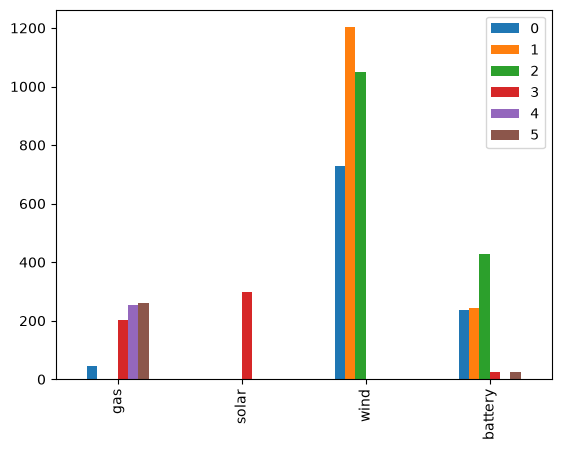

In [9]:
mga_alternatives.plot.bar()

<Axes: >

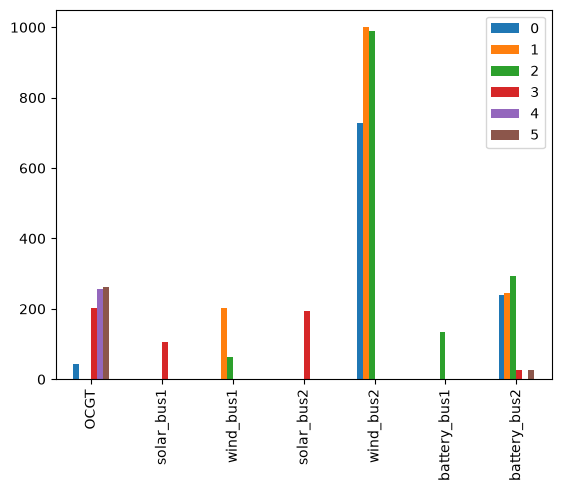

In [10]:
mga_spatial_alternatives.plot.bar()

In [11]:
mga_weights

,1,2,3,4,5
gas,0,-1,0.41,-1,-1
solar,0,0,-0.57,0,1
wind,-1,-1,0.93,1,1
battery,0,-1,0.10,1,0


In [12]:
from mga4all.exploration_metrics import exploration_metrics_progression
from mga4all.model_interface_pypsa import extract_capacity_bounds

# Let's first extract the feasibility bounds of the model, needed for the Shannon index.
bounds_spatial, bounds_aggregate = extract_capacity_bounds(n, test_config)

# Then, let's generate diversity metrics with the pre-built functionality
metrics = exploration_metrics_progression(mga_alternatives, lb=bounds_aggregate['lb'], ub=bounds_aggregate['ub'])

Technologies [] not found in the model


<Axes: >

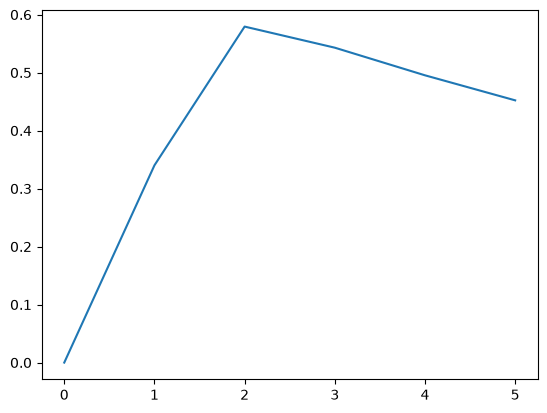

In [13]:
metrics['Shannon'].plot()

<Axes: >

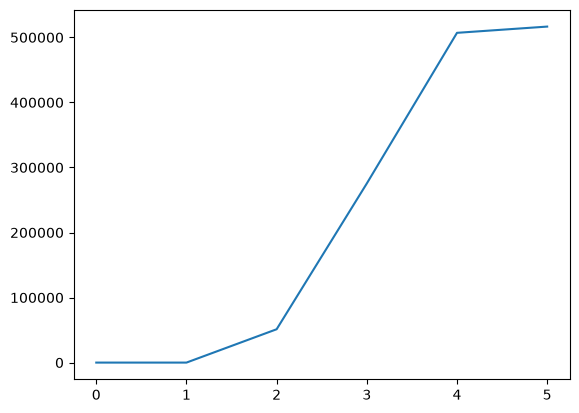

In [14]:
metrics['VESA'].plot()

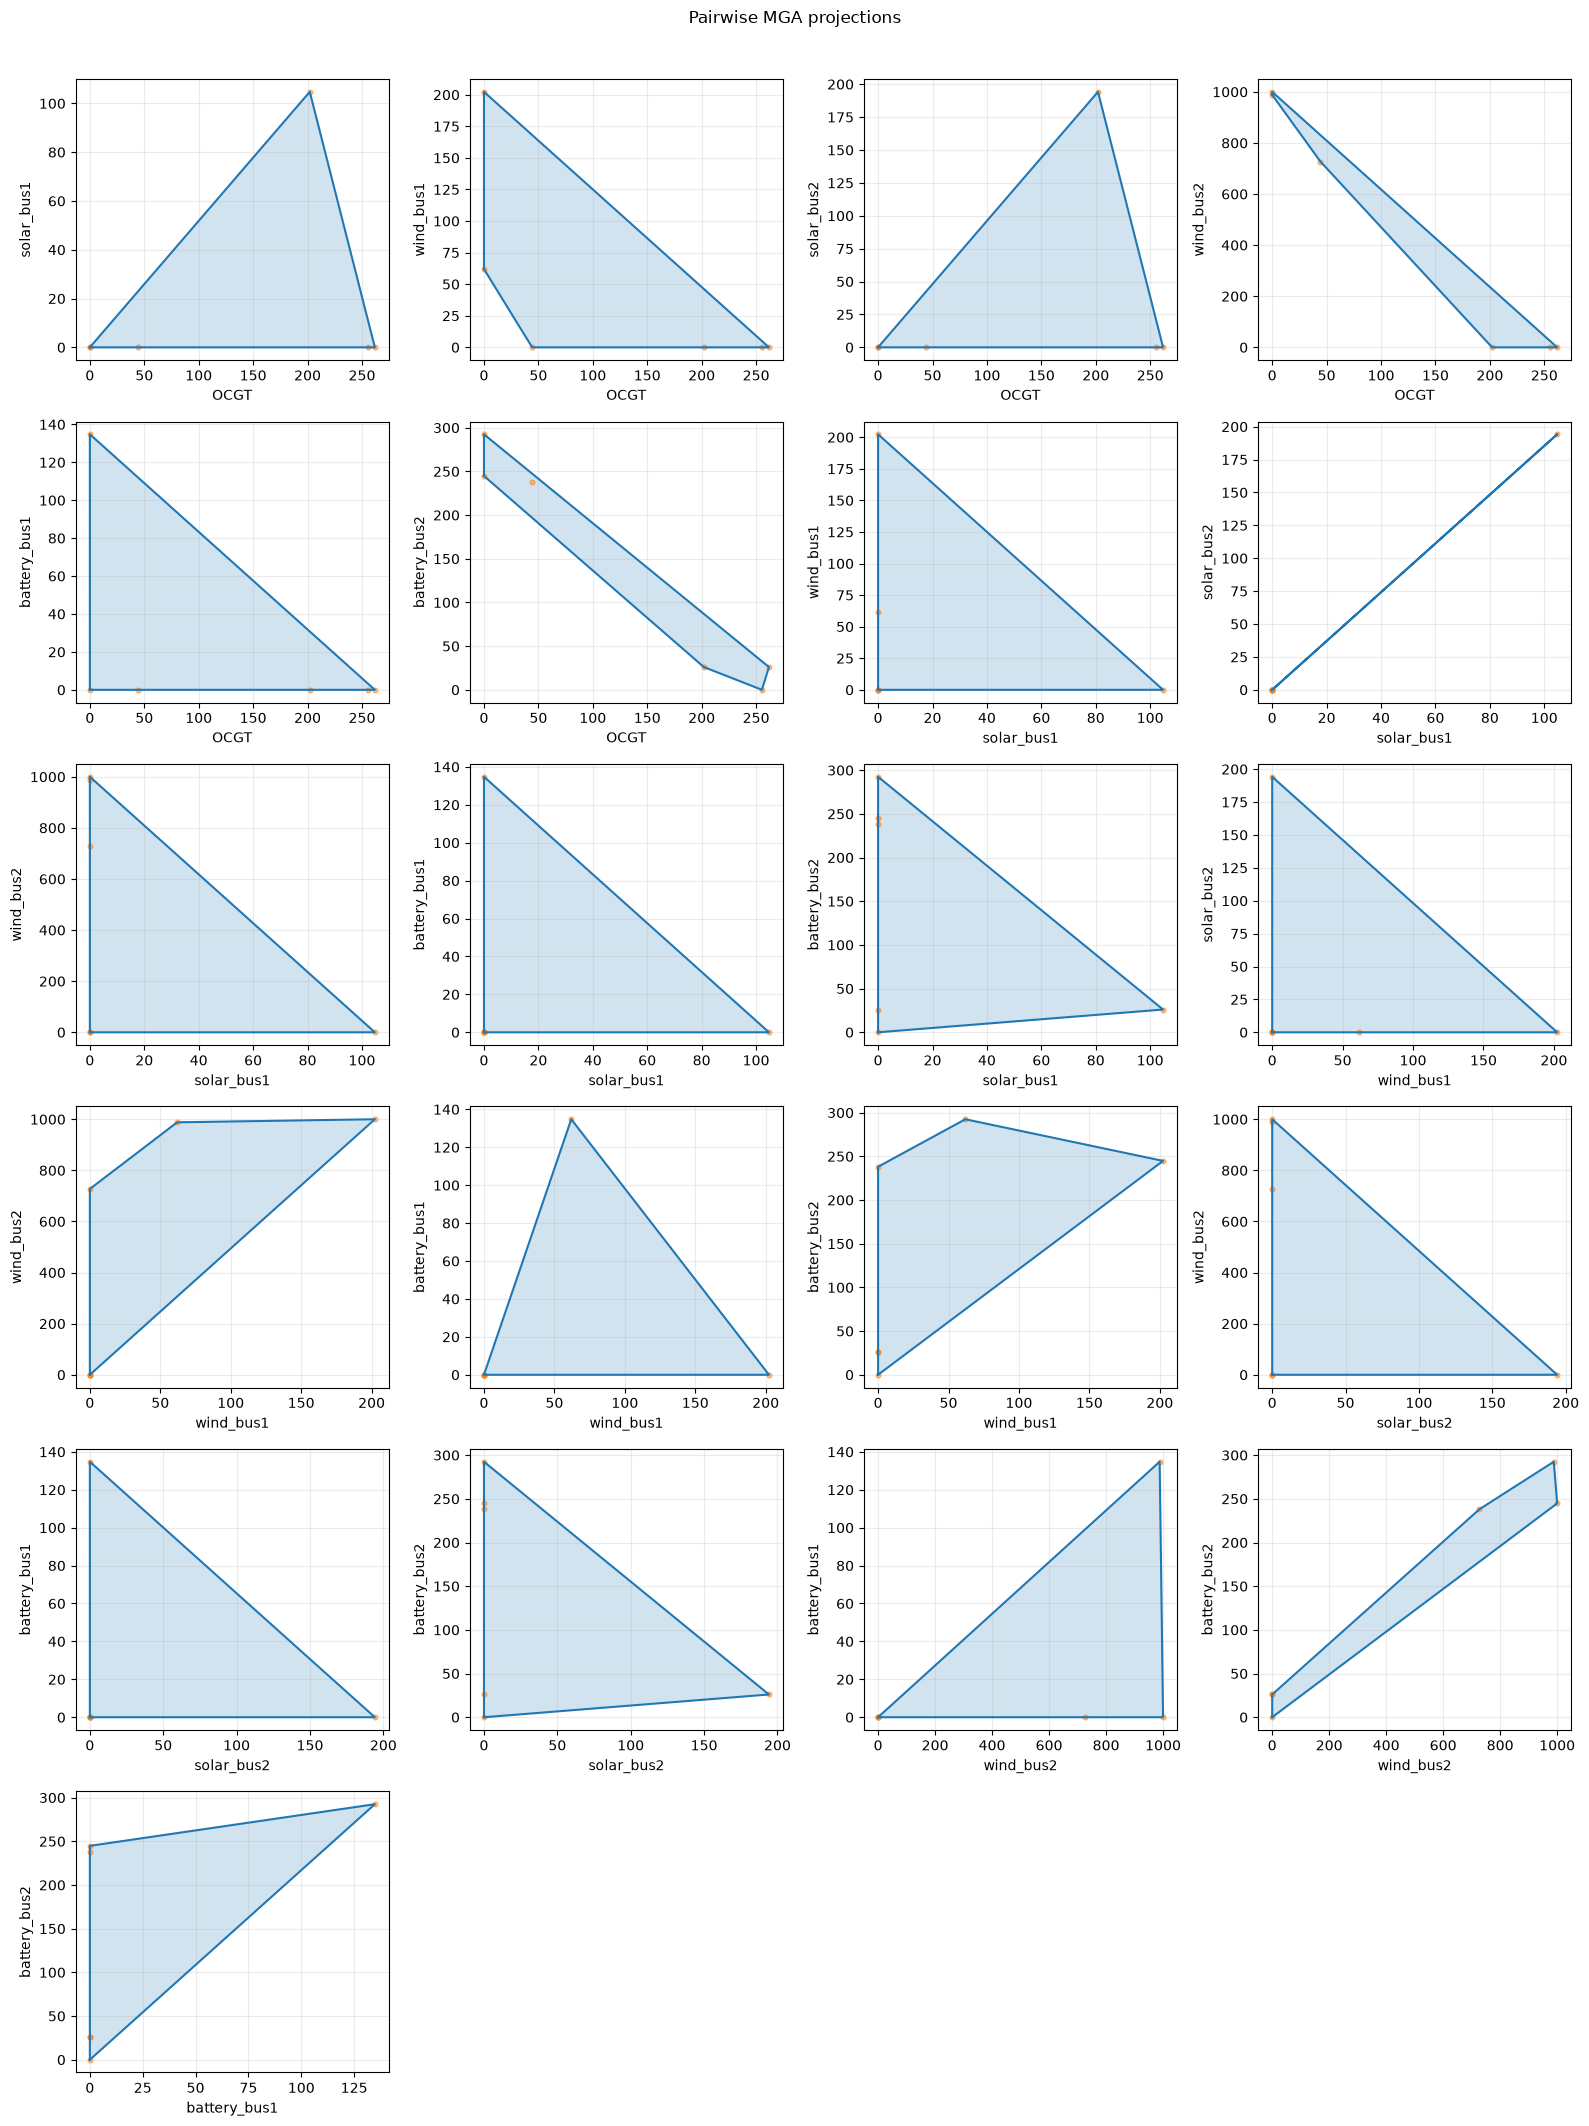

In [15]:
from mga4all.exploration_metrics import plot_vesa_projections
# Let's plot as well the 2D convex hull per spatially-explicit technology pairs
fig, axes = plot_vesa_projections(mga_spatial_alternatives, ncols=4)